In [1]:
!nvidia-smi

Thu Sep 19 10:00:13 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off | 00000000:00:04.0 Off |                    0 |
| N/A   34C    P0              46W / 400W |      2MiB / 40960MiB |      0%      Default |
|                                         |                      |             Disabled |
+-----------------------------------------+----------------------+--

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLOv8

⚠️ YOLOv8 is still under heavy development. Breaking changes are being introduced almost weekly. We strive to make our YOLOv8 notebooks work with the latest version of the library. Last tests took place on **03.01.2024** with version **YOLOv8.0.196**.

If you notice that our notebook behaves incorrectly - especially if you experience errors that prevent you from going through the tutorial - don't hesitate! Let us know and open an [issue](https://github.com/roboflow/notebooks/issues) on the Roboflow Notebooks repository.

YOLOv8 can be installed in two ways - from the source and via pip. This is because it is the first iteration of YOLO to have an official package.

In [3]:
# Pip install method (recommended)

!pip install ultralytics==8.0.196

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.0.196 🚀 Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
Setup complete ✅ (12 CPUs, 83.5 GB RAM, 37.3/235.7 GB disk)


In [ ]:
# Git clone method (for development)

# %cd {HOME}
# !git clone github.com/ultralytics/ultralytics
# %cd {HOME}/ultralytics
# !pip install -e .

# from IPython import display
# display.clear_output()

# import ultralytics
# ultralytics.checks()

In [4]:
from ultralytics import YOLO

from IPython.display import display, Image

## CLI Basics

If you want to train, validate or run inference on models and don't need to make any modifications to the code, using YOLO command line interface is the easiest way to get started. Read more about CLI in [Ultralytics YOLO Docs](https://docs.ultralytics.com/usage/cli/).

```
yolo task=detect    mode=train    model=yolov8n.yaml      args...
          classify       predict        yolov8n-cls.yaml  args...
          segment        val            yolov8n-seg.yaml  args...
                         export         yolov8n.pt        format=onnx  args...
```

## Inference with Pre-trained COCO Model

### 💻 CLI

`yolo mode=predict` runs YOLOv8 inference on a variety of sources, downloading models automatically from the latest YOLOv8 release, and saving results to `runs/predict`.

In [ ]:
%cd {HOME}
!yolo task=detect mode=predict model=yolov8n.pt conf=0.25 source='https://media.roboflow.com/notebooks/examples/dog.jpeg' save=True

/content
100% 6.23M/6.23M [00:00<00:00, 328MB/s]
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/tasks.py:567: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return to

/content


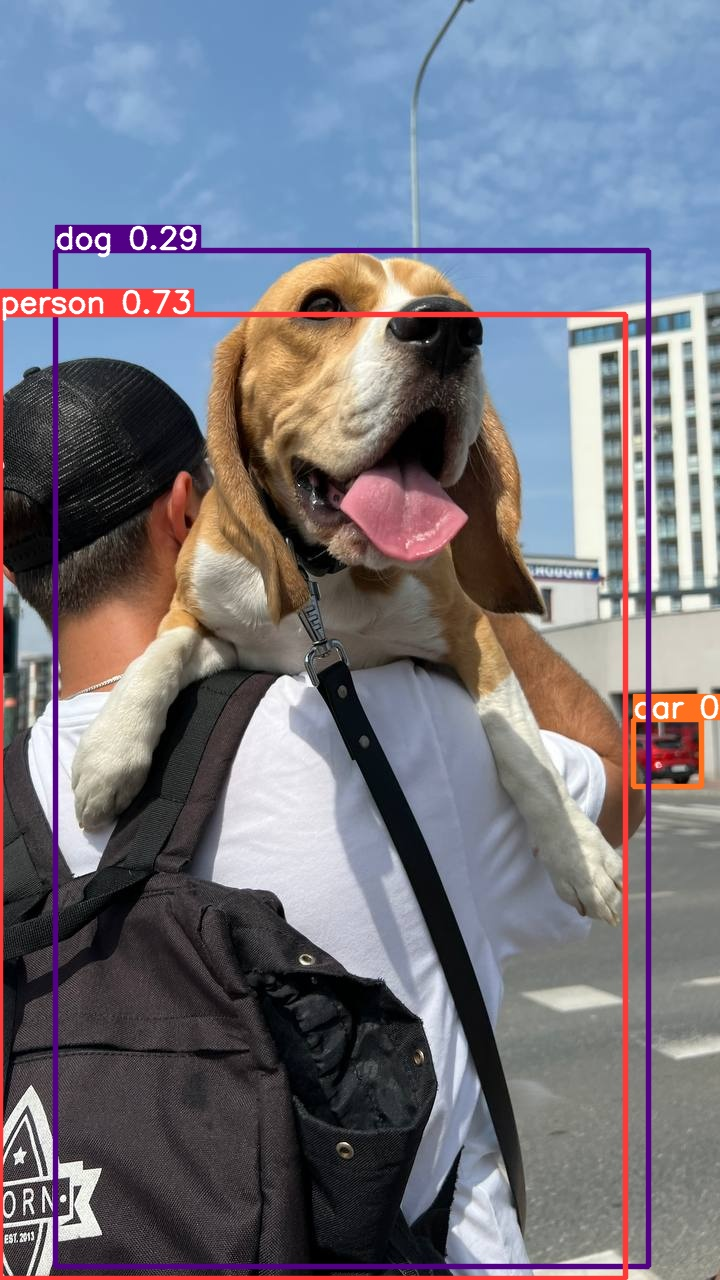

In [ ]:
%cd {HOME}
Image(filename='runs/detect/predict/dog.jpeg', height=600)

### 🐍 Python SDK

The simplest way of simply using YOLOv8 directly in a Python environment.

In [ ]:
model = YOLO(f'{HOME}/yolov8n.pt')
results = model.predict(source='https://media.roboflow.com/notebooks/examples/dog.jpeg', conf=0.25)

/usr/local/lib/python3.10/dist-packages/ultralytics/nn/tasks.py:567: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(file, map_location='cpu'), file  # load


In [ ]:
results[0].boxes.xyxy

tensor([[   0.0000,  314.5054,  625.0387, 1278.1901],
        [  55.3276,  250.0223,  648.1048, 1266.2391],
        [ 633.2264,  719.5393,  701.0568,  786.0264]], device='cuda:0')

In [ ]:
results[0].boxes.conf

tensor([0.7269, 0.2905, 0.2843], device='cuda:0')

In [ ]:
results[0].boxes.cls

tensor([ 0., 16.,  2.], device='cuda:0')

In [5]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

!pip install roboflow --quiet

from roboflow import Roboflow
rf = Roboflow(api_key="2ffl1zZqwCdjI4cj61VQ")
project = rf.workspace("work-r9avx").project("sc_save")
version = project.version(2)
dataset = version.download("yolov8")


/content/datasets
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.3 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SC_SAVE-2 in yolov8:: 100%|██████████| 3028/3028 [00:00<00:00, 8028.57it/s]


## Custom Training

In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolov8s.pt data={dataset.location}/data.yaml epochs=600 imgsz=640 plots=True patience=300

/content
100% 21.5M/21.5M [00:00<00:00, 43.1MB/s]
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/tasks.py:567: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return t

In [ ]:
!ls {HOME}/runs/detect/train/

args.yaml					    R_curve.png		  val_batch0_labels.jpg
confusion_matrix_normalized.png			    results.csv		  val_batch0_pred.jpg
confusion_matrix.png				    results.png		  val_batch1_labels.jpg
events.out.tfevents.1726053865.e7c8fba960d5.7729.0  train_batch0.jpg	  val_batch1_pred.jpg
F1_curve.png					    train_batch1.jpg	  val_batch2_labels.jpg
labels_correlogram.jpg				    train_batch2.jpg	  val_batch2_pred.jpg
labels.jpg					    train_batch38940.jpg  weights
P_curve.png					    train_batch38941.jpg
PR_curve.png					    train_batch38942.jpg


/content


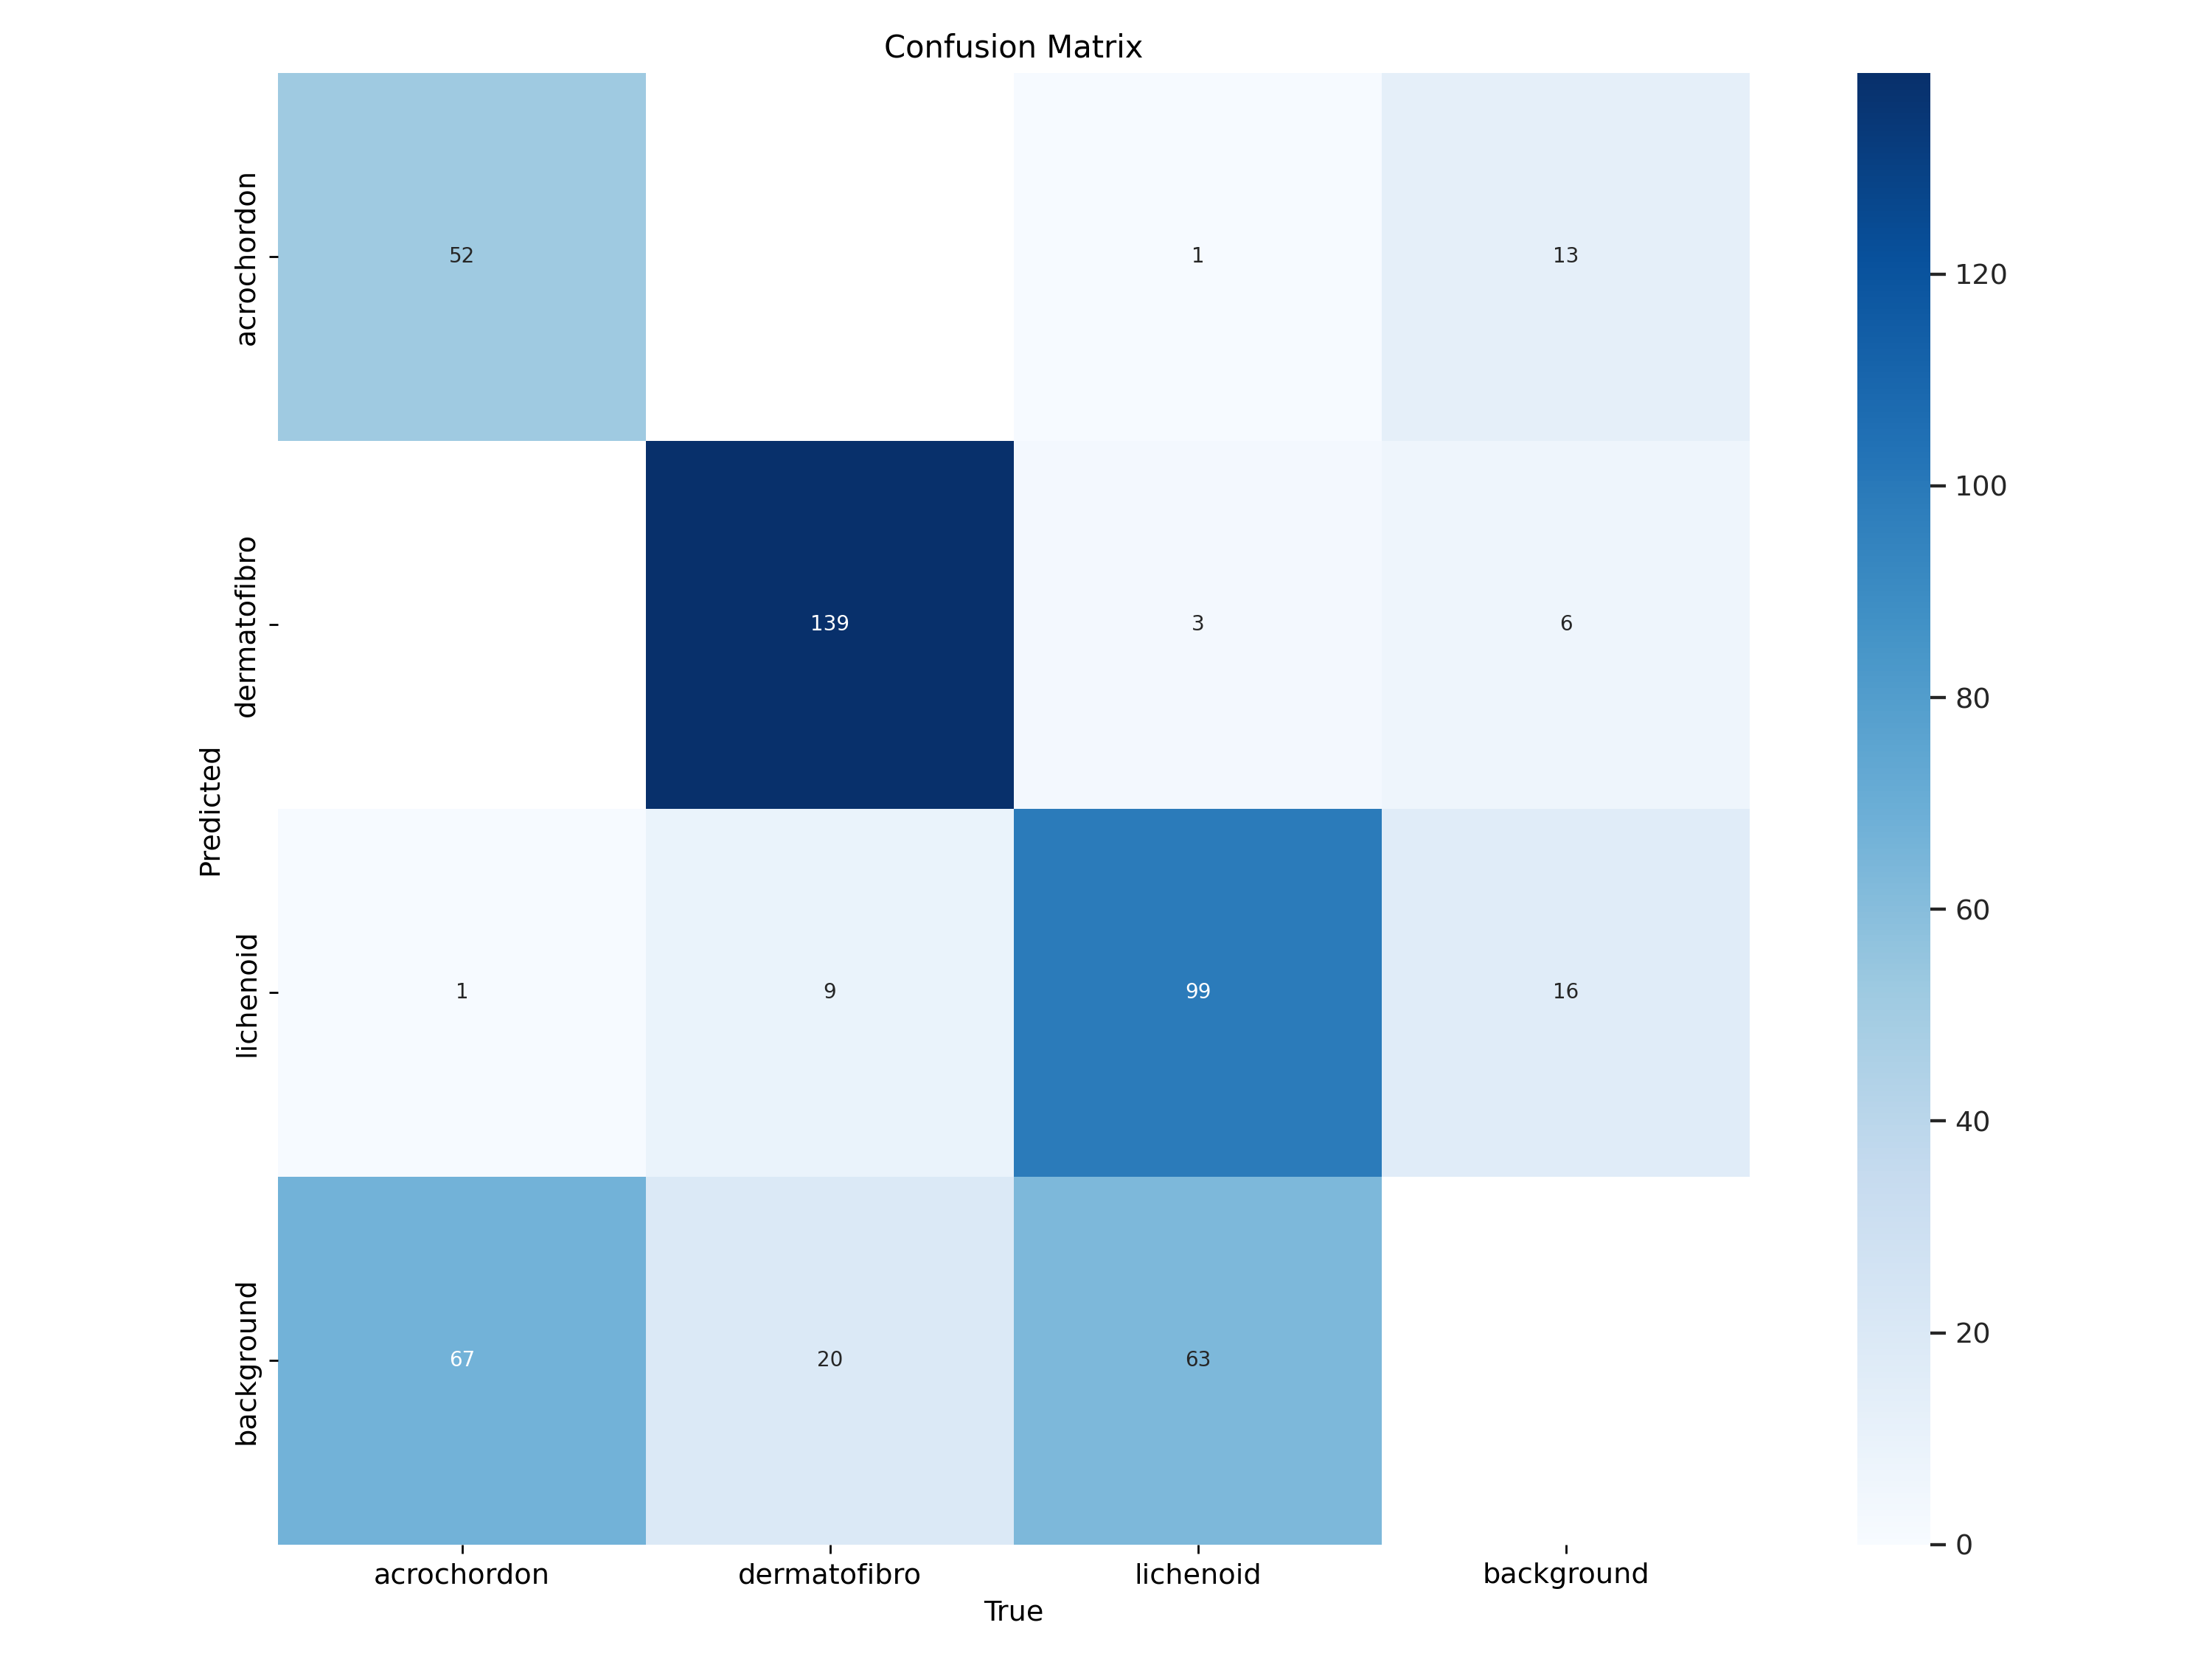

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/confusion_matrix.png', width=600)

/content


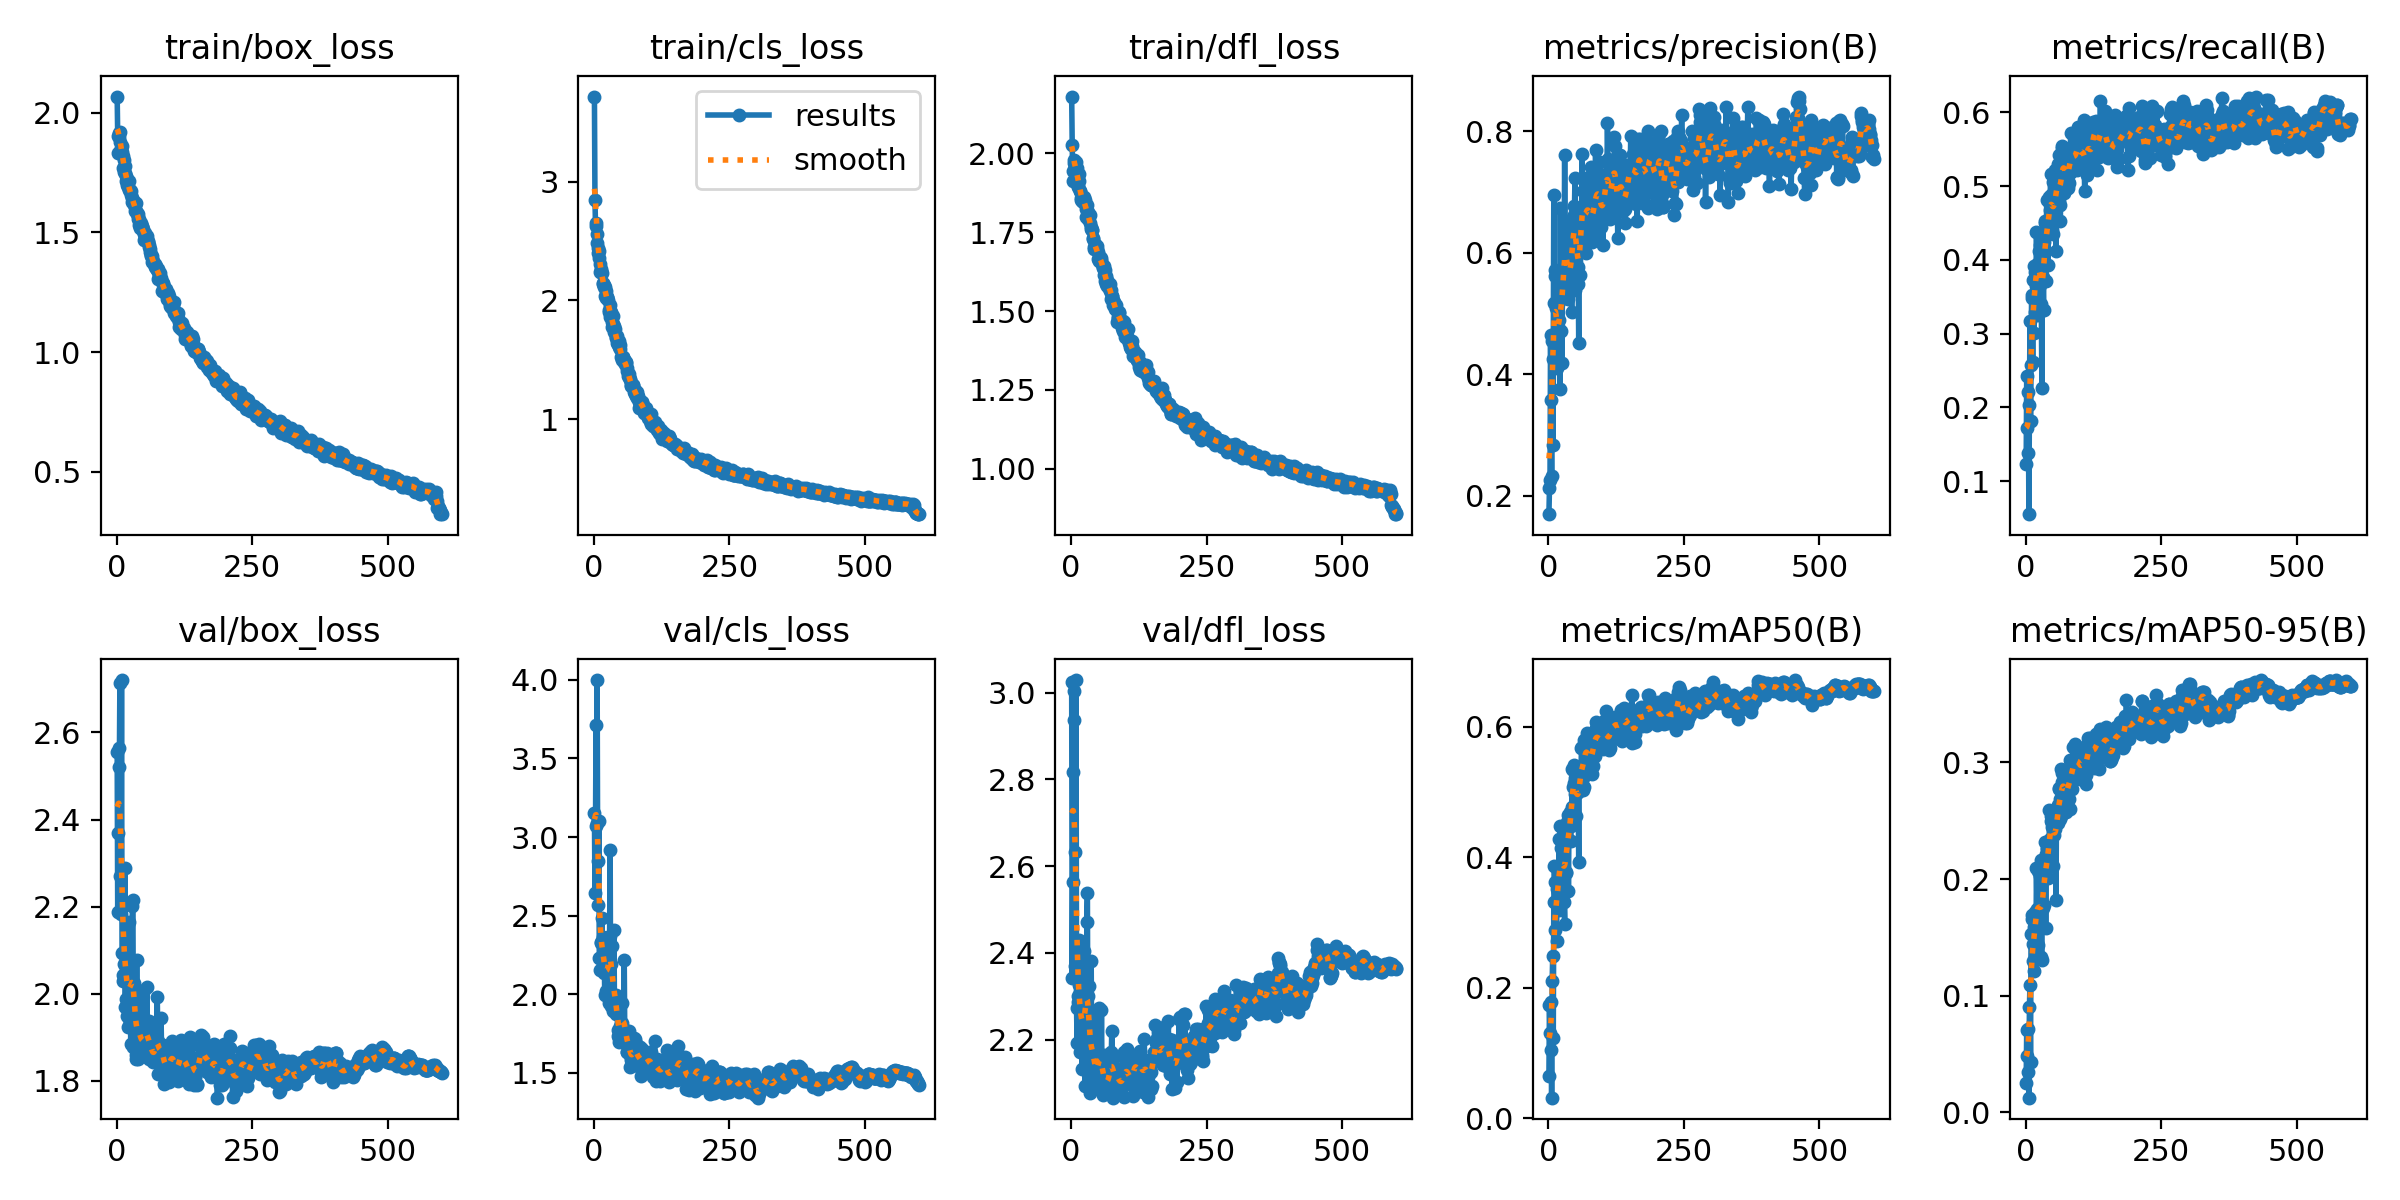

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/results.png', width=600)

/content


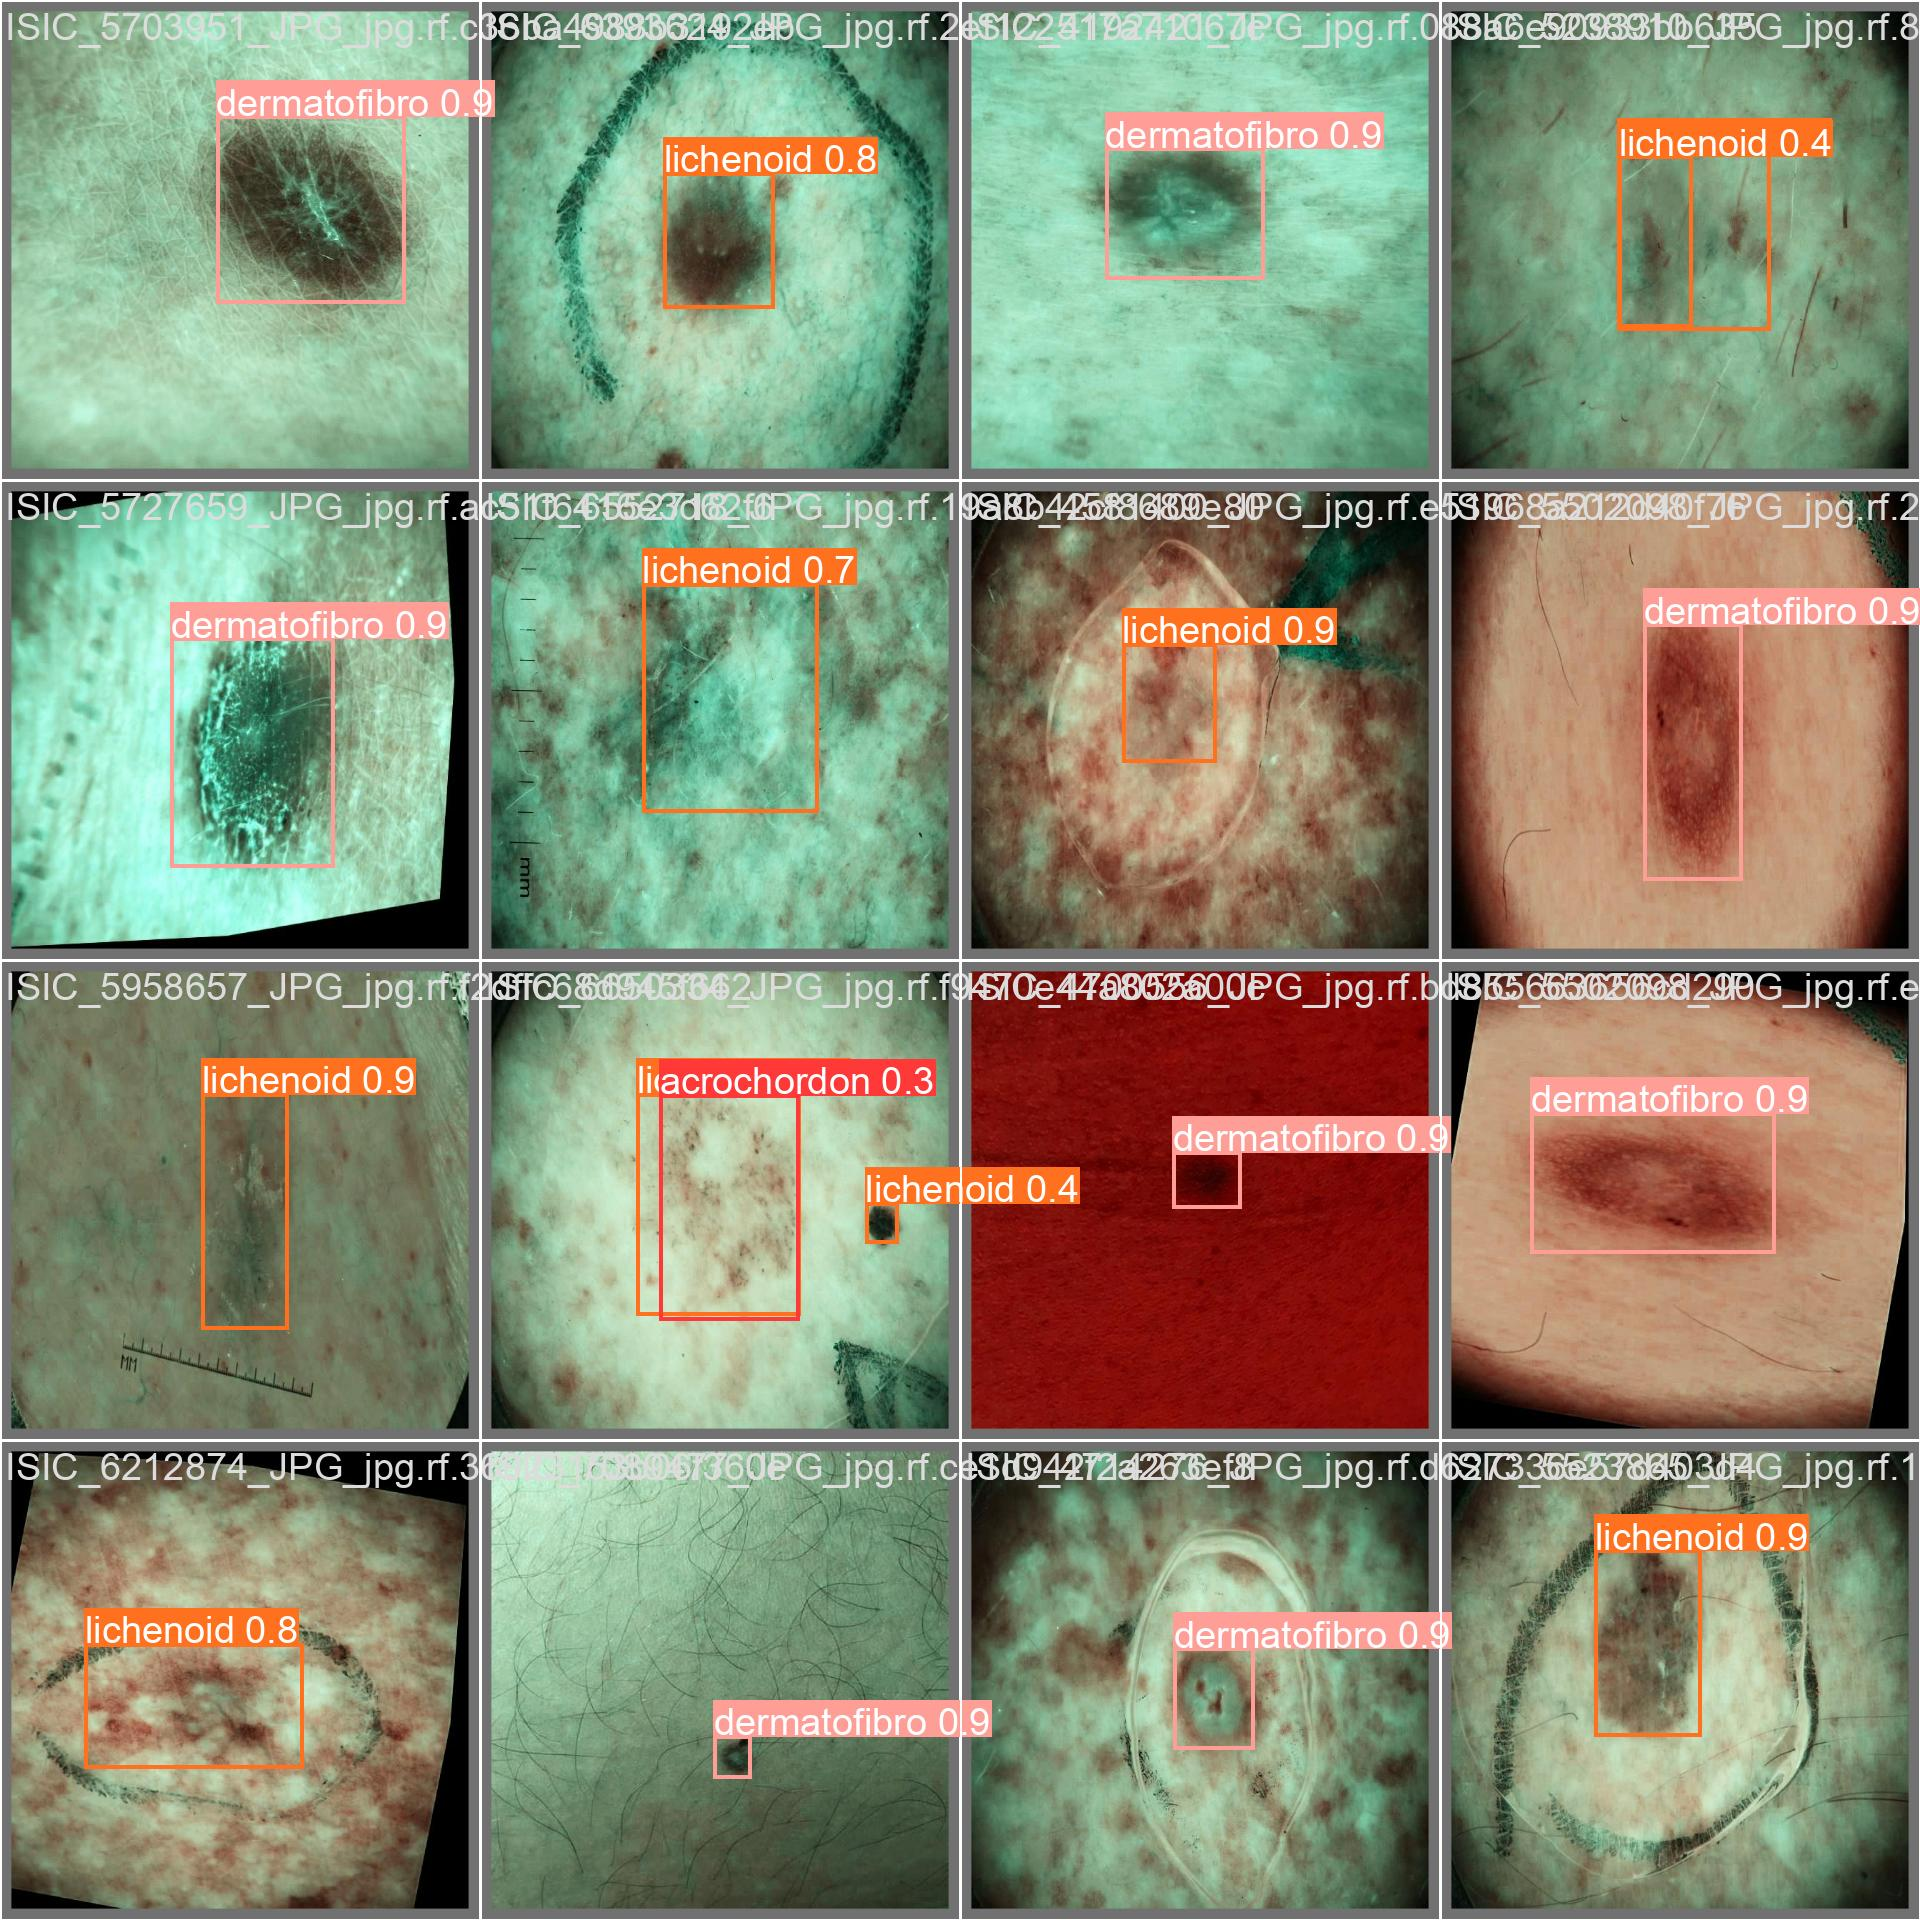

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

## Validate Custom Model

In [ ]:
%cd {HOME}

!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

/content
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/tasks.py:567: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(file, map_location='cpu'), file

In [6]:
%cd {HOME}

!yolo task=detect mode=val model=/content/best.pt data={dataset.location}/data.yaml

/content
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/tasks.py:567: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(file, map_location='cpu'), file

In [7]:
!zip -r /content/runs/detect/valV8SAVE.zip /content/runs/detect/val
from google.colab import files
files.download("/content/runs/detect/valV8SAVE.zip")

  adding: content/runs/detect/val/ (stored 0%)
  adding: content/runs/detect/val/PR_curve.png (deflated 13%)
  adding: content/runs/detect/val/val_batch0_pred.jpg (deflated 9%)
  adding: content/runs/detect/val/confusion_matrix.png (deflated 30%)
  adding: content/runs/detect/val/val_batch1_labels.jpg (deflated 11%)
  adding: content/runs/detect/val/confusion_matrix_normalized.png (deflated 26%)
  adding: content/runs/detect/val/val_batch2_pred.jpg (deflated 9%)
  adding: content/runs/detect/val/R_curve.png (deflated 13%)
  adding: content/runs/detect/val/val_batch0_labels.jpg (deflated 10%)
  adding: content/runs/detect/val/val_batch1_pred.jpg (deflated 11%)
  adding: content/runs/detect/val/val_batch2_labels.jpg (deflated 9%)
  adding: content/runs/detect/val/P_curve.png (deflated 13%)
  adding: content/runs/detect/val/F1_curve.png (deflated 12%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Inference with Custom Model

In [ ]:
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

/content
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/tasks.py:567: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(file, map_location='cpu'), file

In [ ]:
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.25 source=/content/datasets/SC_SAVE-2/test/images save=True save_conf=True save_txt=True

/content
/usr/local/lib/python3.10/dist-packages/ultralytics/nn/tasks.py:567: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(file, map_location='cpu'), file

Mismatched lengths for ISIC_0023959_JPG_jpg.rf.aee498d464ae70a07d2080eeb2f400ad.txt: Ground truth - 1, Predictions - 2
No prediction file found for ISIC_0022057_JPG_jpg.rf.7202cba90fca8803173a2d2be82da49c.txt
Mismatched lengths for ISIC_0013259_JPG_jpg.rf.d69c85e608ba089ac972bbfb30c05177.txt: Ground truth - 4, Predictions - 2
Mismatched lengths for ISIC_0022114_JPG_jpg.rf.a8ced0a463d869e1eca784201c93c8ef.txt: Ground truth - 3, Predictions - 1
Mismatched lengths for ISIC_0013202_JPG_jpg.rf.9831eceda935cfc4b223cdb7051d2c01.txt: Ground truth - 2, Predictions - 1
Mismatched lengths for ISIC_0022520_JPG_jpg.rf.8f1581d7c070de0e2b461854761b98f2.txt: Ground truth - 3, Predictions - 1
Mismatched lengths for ISIC_0013259_JPG_jpg.rf.f4d82b77e4eb39c48244529bd15b2734.txt: Ground truth - 4, Predictions - 1
Mismatched lengths for ISIC_0023975_JPG_jpg.rf.e10a9a283ad06423e8507e62d6557770.txt: Ground truth - 3, Predictions - 1
No prediction file found for ISIC_0021629_JPG_jpg.rf.bb12b411fc01e6013723a45b

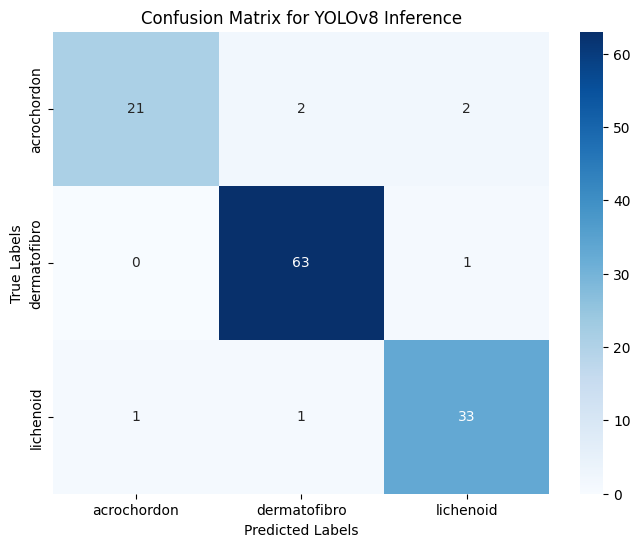

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Path to ground truth and predictions (adjust paths)
ground_truth_path = '/content/datasets/SC_SAVE-2/test/labels'
predictions_path = '/content/runs/detect/predict3/labels'

class_names = ['acrochordon', 'dermatofibro', 'lichenoid']  # Your 3 classes

# Initialize lists to store labels
ground_truth_labels = []
predicted_labels = []

# Function to read labels from txt files
def read_labels(file_path):
    labels = []
    with open(file_path, 'r') as f:
        for line in f:
            label = int(line.split()[0])  # Class ID is the first element
            labels.append(label)
    return labels

# Loop through ground truth files
for filename in os.listdir(ground_truth_path):
    if filename.endswith('.txt'):
        # Read ground truth labels
        gt_labels = read_labels(os.path.join(ground_truth_path, filename))

        # Read predicted labels (if available)
        pred_file = os.path.join(predictions_path, filename)
        if os.path.exists(pred_file):
            pred_labels = read_labels(pred_file)
            # Ensure both lists have the same length for comparison
            if len(gt_labels) == len(pred_labels):
                ground_truth_labels.extend(gt_labels)
                predicted_labels.extend(pred_labels)
            else:
                # Handle cases with mismatched lengths (e.g., add -1 or skip)
                print(f"Mismatched lengths for {filename}: Ground truth - {len(gt_labels)}, Predictions - {len(pred_labels)}")
                #Instead of adding -1 to predicted labels, skip the file
                continue

        else:
            print(f"No prediction file found for {filename}")
            #Instead of adding -1 to predicted labels, skip the file
            continue

# Compute the confusion matrix
cm = confusion_matrix(ground_truth_labels, predicted_labels, labels=[0, 1, 2])

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for YOLOv8 Inference')
plt.show()

In [ ]:
# Function to calculate precision and recall using True Positives, False Positives, and False Negatives
def calculate_precision_recall(TP, FP, FN):
    # Precision calculation
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    # Recall calculation
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    return precision, recall

# Values for each class
classes = {
    "Acrochordon": {"TP": 21, "FP": 3, "FN": 3},
    "Dermatofibro": {"TP": 63, "FP": 2, "FN": 2},
    "Lichenoid": {"TP": 33, "FP": 2, "FN": 3}
}

# Calculate and print precision and recall for each class
for class_name, values in classes.items():
    precision, recall = calculate_precision_recall(values['TP'], values['FP'], values['FN'])
    print(f"{class_name}: Precision = {precision:.2f}, Recall = {recall:.2f}")

Acrochordon: Precision = 0.88, Recall = 0.88
Dermatofibro: Precision = 0.97, Recall = 0.97
Lichenoid: Precision = 0.94, Recall = 0.92


**NOTE:** Let's take a look at few results.

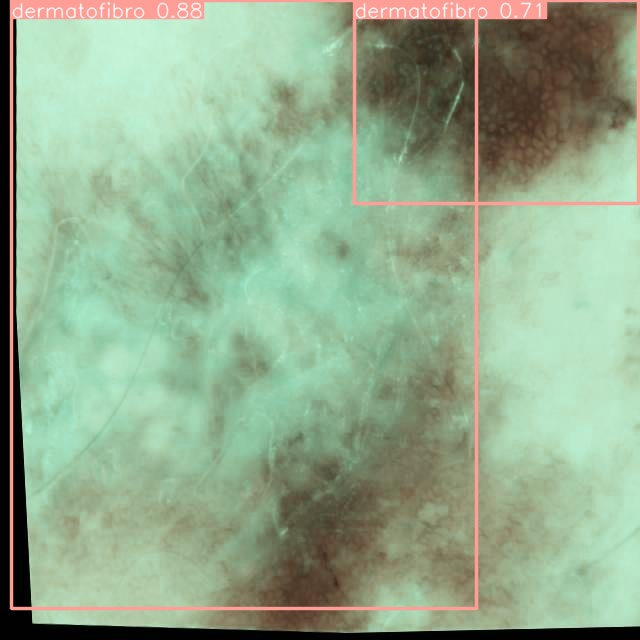

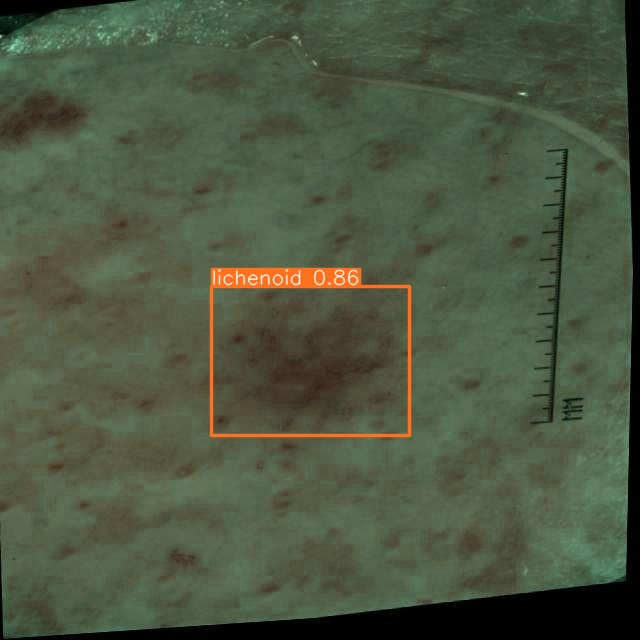

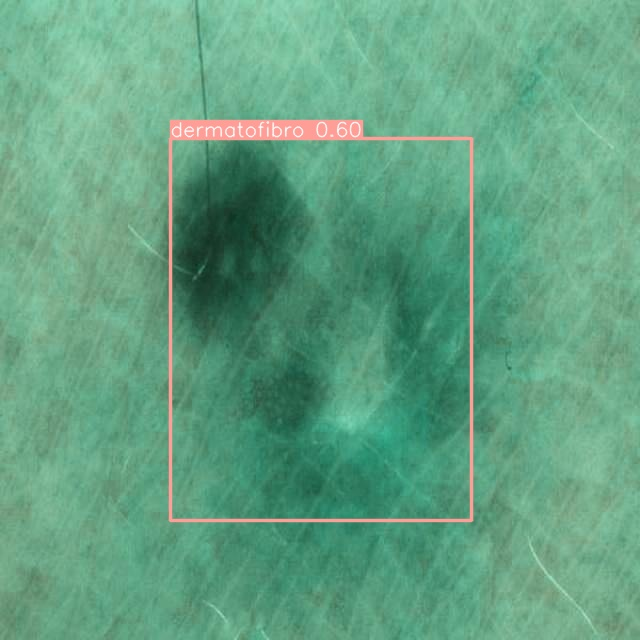

In [ ]:
import glob
from IPython.display import Image, display

for image_path in glob.glob(f'{HOME}/runs/detect/predict3/*.jpg')[:3]:
      display(Image(filename=image_path, width=600))
      print("\n")

In [ ]:
!zip -r /content/runsV8SAVE.zip /content/runs
from google.colab import files
files.download("/content/runsV8SAVE.zip")

  adding: content/runs/ (stored 0%)
  adding: content/runs/detect/ (stored 0%)
  adding: content/runs/detect/train/ (stored 0%)
  adding: content/runs/detect/train/val_batch1_pred.jpg (deflated 10%)
  adding: content/runs/detect/train/train_batch38942.jpg (deflated 10%)
  adding: content/runs/detect/train/P_curve.png (deflated 12%)
  adding: content/runs/detect/train/train_batch38940.jpg (deflated 10%)
  adding: content/runs/detect/train/val_batch1_labels.jpg (deflated 10%)
  adding: content/runs/detect/train/confusion_matrix_normalized.png (deflated 26%)
  adding: content/runs/detect/train/val_batch2_pred.jpg (deflated 10%)
  adding: content/runs/detect/train/val_batch0_pred.jpg (deflated 8%)
  adding: content/runs/detect/train/weights/ (stored 0%)
  adding: content/runs/detect/train/weights/best.pt (deflated 8%)
  adding: content/runs/detect/train/weights/last.pt (deflated 8%)
  adding: content/runs/detect/train/train_batch38941.jpg (deflated 8%)
  adding: content/runs/detect/train/P

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Deploy model on Roboflow

Once you have finished training your YOLOv8 model, you’ll have a set of trained weights ready for use. These weights will be in the `/runs/detect/train/weights/best.pt` folder of your project. You can upload your model weights to Roboflow Deploy to use your trained weights on our infinitely scalable infrastructure.

The `.deploy()` function in the [Roboflow pip package](https://docs.roboflow.com/python) now supports uploading YOLOv8 weights.

To upload model weights, add the following code to the “Inference with Custom Model” section in the aforementioned notebook:

In [ ]:
project.version(dataset.version).deploy(model_type="yolov8", model_path=f"{HOME}/runs/detect/train/")

View the status of your deployment at: https://app.roboflow.com/roboflow-jvuqo/football-players-detection-3zvbc/1
Share your model with the world at: https://universe.roboflow.com/roboflow-jvuqo/football-players-detection-3zvbc/1


In [ ]:
#While your deployment is processing, checkout the deployment docs to take your model to most destinations https://docs.roboflow.com/inference

In [ ]:
#Run inference on your model on a persistant, auto-scaling, cloud API

#load model
model = project.version(dataset.version).model

#choose random test set image
import os, random
test_set_loc = dataset.location + "/test/images/"
random_test_image = random.choice(os.listdir(test_set_loc))
print("running inference on " + random_test_image)

pred = model.predict(test_set_loc + random_test_image, confidence=40, overlap=30).json()
pred